# An agent for automated curve-fitting of battery degradation data

Walkthrough of the full run on all 139 cells from the Severson et al. (2019) A123 LFP/graphite fast-charge dataset.
The agent is a LangGraph state machine that, for every cell, extracts clean capacity-vs-cycle points, fits seven
candidate degradation laws, asks a local LLM (Llama 3.1 8B via Ollama) whether a human should look at the cell,
runs a deep dive with more flexible models on flagged cells, plots the result and writes a fleet-level report.

The same code is packaged in `battery_fit_agent/` and runs from the command line with `python run_agent.py`.
This notebook keeps the inline version so the outputs of the run can be read top to bottom.
To keep it small enough to render on GitHub, per-cell plots are shown only for the high-priority shortlist; all plots are written to `agent_outputs/plots/`.

**Data:** per-cell CSVs (`cycle_index`, `discharge_capacity`) in `data/battery_data_store/`, produced with
`scripts/extract_cycle_csvs.py`.

## Setup and configuration

In [1]:
# Configuration
import os, glob, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, OptimizeWarning
from scipy.interpolate import UnivariateSpline
from typing import TypedDict
from langchain_ollama import ChatOllama
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END

warnings.filterwarnings("ignore", category=OptimizeWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA_STORE = "../data/battery_data_store"          # folder of per-cell CSVs from extract_cycle_csvs.py
OUT_DIR    = "../agent_outputs"
PLOT_DIR   = os.path.join(OUT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

MODEL      = "llama3.1:8b"
OLLAMA_URL = "http://localhost:11434"
llm_json = ChatOllama(model=MODEL, temperature=0, format="json", base_url=OLLAMA_URL)  # structured decisions
llm_text = ChatOllama(model=MODEL, temperature=0, base_url=OLLAMA_URL)                 # written summary

NOMINAL_AH = 1.1          # A123 APR18650M1A
EOL_AH     = 0.88         # 80 % of nominal
files = sorted(glob.glob(os.path.join(DATA_STORE, "*.csv")))
print(f"{len(files)} cell files in {DATA_STORE}:", [os.path.basename(f) for f in files[:5]], "...")

139 cell files in ../data/battery_data_store: ['FastCharge_000000_CH19.csv', 'FastCharge_000001_CH16.csv', 'FastCharge_000001_CH30.csv', 'FastCharge_000001_CH38.csv', 'FastCharge_000002_CH10.csv'] ...


## Tool 1: load a cell and extract clean data points

In [2]:
# Tools 1/3 : read a file and extract the data points of interest
def load_and_extract(path):
    """Read one cell's per-cycle CSV and return clean discharge-capacity-vs-cycle points
    plus data-quality facts (outliers removed, capacity-recovery jumps after rests)."""
    df = pd.read_csv(path)
    df.columns = [c.lower().strip() for c in df.columns]
    df = df.rename(columns={"qd": "discharge_capacity"})
    if "cycle_index" not in df.columns:
        df["cycle_index"] = np.arange(1, len(df) + 1)
    df = df[(df["cycle_index"] > 0)].dropna(subset=["discharge_capacity"])

    n_all = df["cycle_index"].to_numpy(float)
    q_all = df["discharge_capacity"].to_numpy(float)

    # ---- hard glitches : physically impossible capacities ----
    ok = (q_all > 0.5) & (q_all < 1.3)
    # ---- soft outliers : points far from a rolling median ----
    med = pd.Series(np.where(ok, q_all, np.nan)).rolling(21, center=True, min_periods=5).median().to_numpy()
    resid = q_all - med
    mad = np.nanmedian(np.abs(resid[ok] - np.nanmedian(resid[ok]))) * 1.4826
    ok &= np.abs(resid) <= max(6 * mad, 0.01)

    n, q = n_all[ok], q_all[ok]
    noise = float(np.median(np.abs(np.diff(q))) * 1.4826 / np.sqrt(2))      # cycle-to-cycle noise (Ah)

    # ---- capacity-recovery jumps (typical after rest periods / test pauses) ----
    smooth = pd.Series(q).rolling(5, center=True, min_periods=1).median().to_numpy()
    jumps = np.where(np.diff(smooth) > max(4 * noise, 0.004))[0]
    paused = int((df["paused"] > 0).sum()) if "paused" in df.columns else None

    below = np.where(q < EOL_AH)[0]
    return {
        "cell_id": os.path.splitext(os.path.basename(path))[0],
        "n": n, "q": q,
        "outlier_n": n_all[~ok], "outlier_q": q_all[~ok],
        "facts": {
            "cycles": int(len(n)), "first_cycle": int(n[0]), "last_cycle": int(n[-1]),
            "q_start_Ah": round(float(np.median(q[:10])), 4), "q_end_Ah": round(float(np.median(q[-10:])), 4),
            "eol_cycle": int(n[below[0]]) if len(below) else None,
            "outliers_removed": int((~ok).sum()), "noise_Ah": round(noise, 5),
            "recovery_jumps": int(len(jumps)), "paused_cycles": paused,
        },
    }

## Tool 2: candidate functions, fitting and goodness-of-fit

Seven parametric candidates are ranked by BIC. Flagged cells get two flexible models in the deep dive (2-break piecewise linear, smoothing spline).

In [3]:
# Tools 2/3 : candidate functions, fitting and goodness-of-fit
def _metrics(y, yhat, k):
    rss = float(np.sum((y - yhat) ** 2)); m = len(y)
    return {"rmse_mAh": 1e3 * np.sqrt(rss / m),
            "r2": 1 - rss / float(np.sum((y - y.mean()) ** 2)),
            "aic": m * np.log(rss / m) + 2 * k,
            "bic": m * np.log(rss / m) + k * np.log(m), "k": k}

def _hinge(x, y, breaks):
    """Continuous piecewise-linear fit with fixed breakpoints (linear least squares)."""
    X = np.column_stack([np.ones_like(x), x] + [np.maximum(0, x - b) for b in breaks])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return X @ coef, coef

def fit_piecewise(x, y, n_breaks=1):
    """Grid-search the breakpoint(s); returns the best continuous piecewise-linear fit."""
    grid = np.quantile(x, np.linspace(0.05, 0.97, 60 if n_breaks == 1 else 25))
    best = None
    cands = [(b,) for b in grid] if n_breaks == 1 else [(a, b) for a in grid for b in grid if b > a + 0.05]
    for br in cands:
        yhat, coef = _hinge(x, y, br)
        rss = np.sum((y - yhat) ** 2)
        if best is None or rss < best[0]:
            best = (rss, yhat, br, coef)
    return best[1], best[2], best[3]

def fit_all(n, q, extended=False):
    """Fit every candidate function to capacity-vs-cycle. x is cycle scaled to [0,1] for stability."""
    x = (n - n.min()) / (n.max() - n.min())
    y0, y1 = q[:10].mean(), q[-10:].mean()
    fits = {}

    def add(name, yhat, k, **extra):
        if yhat is not None and np.all(np.isfinite(yhat)):
            fits[name] = {"yhat": yhat, **_metrics(q, yhat, k), **extra}

    # polynomials
    for deg, name in [(1, "linear"), (2, "quadratic"), (3, "cubic")]:
        add(name, np.polyval(np.polyfit(x, q, deg), x), deg + 1)
    # non-linear parametric models
    models = {
        "power":       (lambda x, a, b, c: a - b * np.power(x + 1e-9, c), [y0, max(y0 - y1, 1e-3), 1.5],
                        ([0, 0, 0.1], [2, 2, 15])),
        "exponential": (lambda x, a, b, c: a - b * np.exp(c * x), [y0 + 0.005, 0.005, 4.0],
                        ([0, 1e-9, 0.01], [2, 2, 60])),
        "double_exp":  (lambda x, a, b, c, d: a * np.exp(b * x) + c * np.exp(d * x), [y0, -0.05, -1e-3, 6.0],
                        ([0, -10, -2, 0], [2, 1, 0, 60])),
    }
    for name, (f, p0, bounds) in models.items():
        try:
            p, _ = curve_fit(f, x, q, p0=p0, bounds=bounds, maxfev=20000)
            add(name, f(x, *p), len(p))
        except Exception:
            pass
    # piecewise linear with one breakpoint -> the knee
    yhat, br, coef = fit_piecewise(x, q, 1)
    knee = float(n.min() + br[0] * (n.max() - n.min()))
    add("piecewise_1break", yhat, 4, knee_cycle=round(knee), slope_change=float(coef[2]))

    if extended:   # deep-dive models, only for flagged cells
        yhat, br, _ = fit_piecewise(x, q, 2)
        add("piecewise_2break", yhat, 6,
            breaks=[round(float(n.min() + b * (n.max() - n.min()))) for b in br])
        noise = np.median(np.abs(np.diff(q))) * 1.4826 / np.sqrt(2)
        spl = UnivariateSpline(x, q, s=len(q) * noise ** 2 * 1.5)
        add("smoothing_spline", spl(x), len(spl.get_knots()) + 3)
    return fits

def rank_fits(fits):
    table = pd.DataFrame({m: {k: v for k, v in f.items() if k in ("rmse_mAh", "r2", "aic", "bic", "k")}
                          for m, f in fits.items()}).T
    table["delta_bic"] = table["bic"] - table["bic"].min()
    return table.sort_values("bic").round({"rmse_mAh": 2, "r2": 4, "aic": 1, "bic": 1, "delta_bic": 1})

def compute_signals(facts, fits, table):
    """Deterministic evidence the reviewer (LLM) reasons over."""
    best = table.index[0]
    pw = fits.get("piecewise_1break", {})
    knee_gain = float(table.loc["linear", "bic"] - table.loc["piecewise_1break", "bic"]) \
        if "linear" in table.index and "piecewise_1break" in table.index else 0.0
    return {
        "best_model": best,
        "best_rmse_mAh": float(table.iloc[0]["rmse_mAh"]),
        "noise_mAh": round(1e3 * facts["noise_Ah"], 2),
        "fit_to_noise_ratio": round(float(table.iloc[0]["rmse_mAh"]) / max(1e3 * facts["noise_Ah"], 1e-3), 2),
        "runner_up": table.index[1], "runner_up_delta_bic": float(table.iloc[1]["delta_bic"]),
        "knee_cycle": pw.get("knee_cycle"),
        "knee_bic_gain_vs_linear": round(knee_gain, 1),
        "fade_accelerates_after_knee": bool(pw.get("slope_change", 0) < 0),
        "outliers_removed": facts["outliers_removed"], "recovery_jumps": facts["recovery_jumps"],
        "eol_cycle": facts["eol_cycle"], "cycles": facts["cycles"],
    }

def rule_flags(s):
    """Fallback/baseline flags (used if the LLM reply is unusable, and shown to the LLM)."""
    r = []
    if s["fit_to_noise_ratio"] > 2.5:          r.append("no candidate explains the curve (RMSE >> noise)")
    if s["runner_up_delta_bic"] < 2:           r.append("two models fit equally well (ambiguous)")
    if s["outliers_removed"] >= 5:             r.append(f"{s['outliers_removed']} outlier cycles removed")
    if s["recovery_jumps"] >= 3:               r.append(f"{s['recovery_jumps']} capacity-recovery jumps")
    if s["knee_cycle"] and s["fade_accelerates_after_knee"] and s["knee_bic_gain_vs_linear"] > 10 \
       and s["knee_cycle"] < 0.4 * (s["eol_cycle"] or s["cycles"]):
        r.append(f"early knee at cycle {s['knee_cycle']}")
    return r

## Tool 3: diagnostic plot

In [4]:
# Tools 3/3 : plotting
def plot_cell(cell, fits, table, review, path):
    n, q = cell["n"], cell["q"]
    best = table.index[0]
    fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    ax.scatter(n, q, s=6, color="0.6", label="extracted points")
    if len(cell["outlier_n"]):
        ax.scatter(cell["outlier_n"], np.clip(cell["outlier_q"], 0.8, 1.15), marker="x", s=25,
                   color="crimson", label=f"outliers removed ({len(cell['outlier_n'])})")
    for m in table.index:
        ax.plot(n, fits[m]["yhat"], lw=2.6 if m == best else 1.0, alpha=1 if m == best else 0.6,
                label=f"{m}  RMSE={table.loc[m, 'rmse_mAh']:.1f} mAh" + ("  <- best (BIC)" if m == best else ""))
    knee = fits.get("piecewise_1break", {}).get("knee_cycle")
    if knee:
        ax.axvline(knee, color="k", ls=":", lw=1); ax.text(knee, ax.get_ylim()[1], " knee", va="top", fontsize=8)
    ax.axhline(EOL_AH, color="crimson", ls="--", lw=0.8)
    ax.set_ylabel("Discharge capacity (Ah)"); ax.legend(fontsize=7, loc="lower left")
    status = "FLAGGED: " + "; ".join(review.get("reasons", []))[:110] if review.get("flag") else "not flagged"
    ax.set_title(f"{cell['cell_id']}   |   {status}", fontsize=9)
    axr.scatter(n, 1e3 * (q - fits[best]["yhat"]), s=4, color="0.4")
    axr.axhline(0, color="k", lw=0.8); axr.set_ylabel(f"resid. {best}\n(mAh)"); axr.set_xlabel("Cycle")
    plt.tight_layout(); plt.savefig(path, dpi=120); plt.close(fig)

## LLM reviewer

The LLM sees deterministic signals plus the rule-based checks and returns a JSON decision; an unusable reply falls back to the rules.

In [5]:
# LLM reviewer
REVIEW_PROMPT = """You are a battery test engineer reviewing automated curve fits of discharge capacity vs cycle
for one LFP/graphite cell (A123, nominal 1.1 Ah, end of life 0.88 Ah). Decide whether a human should look at this
cell closely. Interesting cells are ones where the fits do not explain the data, the best model is ambiguous,
the data has quality problems (many outliers, capacity-recovery jumps), or degradation is unusual (e.g. an early knee).
A clean curve that one model explains well is NOT interesting.

Reply with JSON only:
{"flag": true or false, "priority": "high" | "medium" | "low", "reasons": ["short reason", ...], "comment": "one sentence"}"""

def llm_review(cell_id, signals, table, rules):
    msg = (f"Cell: {cell_id}\nSignals: {json.dumps(signals)}\n"
           f"Fit table (sorted by BIC):\n{table[['rmse_mAh', 'r2', 'bic', 'delta_bic']].to_string()}\n"
           f"Rule-based checks triggered: {rules or 'none'}")
    try:
        out = json.loads(llm_json.invoke([SystemMessage(content=REVIEW_PROMPT), HumanMessage(content=msg)]).content)
        out["flag"] = bool(out.get("flag")); out.setdefault("reasons", rules); out["source"] = "llm"
        return out
    except Exception as e:                                   # unusable reply -> deterministic fallback
        return {"flag": bool(rules), "priority": "medium" if rules else "low", "reasons": rules,
                "comment": f"LLM review unavailable ({type(e).__name__}); rule-based decision.", "source": "rules"}

## The LangGraph workflow

In [6]:
# The LangGraph workflow
class BatchState(TypedDict):
    queue: list          # files still to process
    current: dict        # the cell being processed (data, fits, table, signals, review)
    results: list        # one summary row per finished cell
    report: str

def next_file(state: BatchState):
    return {}                                                       # routing happens in the edge

def route_next(state: BatchState):
    return "load_extract" if state["queue"] else "summarize"

def load_extract(state: BatchState):
    path, rest = state["queue"][0], state["queue"][1:]
    cell = load_and_extract(path)
    print(f"\n[{cell['cell_id']}] {cell['facts']['cycles']} cycles, "
          f"{cell['facts']['outliers_removed']} outliers removed, {cell['facts']['recovery_jumps']} recovery jumps")
    return {"queue": rest, "current": {"cell": cell}}

def fit_models(state: BatchState):
    cur = dict(state["current"])
    cur["fits"] = fit_all(cur["cell"]["n"], cur["cell"]["q"])
    cur["table"] = rank_fits(cur["fits"])
    cur["signals"] = compute_signals(cur["cell"]["facts"], cur["fits"], cur["table"])
    s = cur["signals"]
    print(f"  best: {s['best_model']} (RMSE {s['best_rmse_mAh']} mAh, noise {s['noise_mAh']} mAh), "
          f"runner-up {s['runner_up']} dBIC={s['runner_up_delta_bic']}, knee ~cycle {s['knee_cycle']}")
    return {"current": cur}

def review(state: BatchState):
    cur = dict(state["current"])
    rules = rule_flags(cur["signals"])
    cur["review"] = llm_review(cur["cell"]["cell_id"], cur["signals"], cur["table"], rules)
    r = cur["review"]
    print(f"  review ({r['source']}): flag={r['flag']} priority={r.get('priority')} reasons={r.get('reasons')}")
    return {"current": cur}

def route_review(state: BatchState):
    return "deep_dive" if state["current"]["review"]["flag"] else "plot"

def deep_dive(state: BatchState):
    """Flagged cells only: try more flexible models and check whether they resolve the issue."""
    cur = dict(state["current"])
    cur["fits"] = fit_all(cur["cell"]["n"], cur["cell"]["q"], extended=True)
    cur["table"] = rank_fits(cur["fits"])
    new_best = cur["table"].index[0]
    ratio = cur["table"].iloc[0]["rmse_mAh"] / max(cur["signals"]["noise_mAh"], 1e-3)
    note = (f"deep-dive best: {new_best} (RMSE/noise {ratio:.2f})"
            + ("; flexible model resolves the misfit" if ratio <= 2.5 else "; still unexplained -> inspect manually"))
    cur["review"] = {**cur["review"], "deep_dive": note}
    if "breaks" in cur["fits"].get("piecewise_2break", {}):
        cur["review"]["deep_dive"] += f"; 2-break piecewise breaks at {cur['fits']['piecewise_2break']['breaks']}"
    print("  " + cur["review"]["deep_dive"])
    return {"current": cur}

def plot(state: BatchState):
    cur = state["current"]
    path = os.path.join(PLOT_DIR, f"{cur['cell']['cell_id']}.png")
    plot_cell(cur["cell"], cur["fits"], cur["table"], cur["review"], path)
    return {"current": {**cur, "plot": path}}

def record(state: BatchState):
    cur = state["current"]; s = cur["signals"]; r = cur["review"]; f = cur["cell"]["facts"]
    row = {"cell_id": cur["cell"]["cell_id"], "cycles": f["cycles"], "eol_cycle": f["eol_cycle"],
           "best_model": cur["table"].index[0], "best_rmse_mAh": float(cur["table"].iloc[0]["rmse_mAh"]),
           "noise_mAh": s["noise_mAh"], "knee_cycle": s["knee_cycle"],
           "outliers": f["outliers_removed"], "recovery_jumps": f["recovery_jumps"],
           "flag": r["flag"], "priority": r.get("priority"), "reasons": "; ".join(r.get("reasons", [])),
           "comment": r.get("comment", ""), "deep_dive": r.get("deep_dive", ""), "plot": cur["plot"]}
    cur["table"].to_csv(os.path.join(OUT_DIR, f"{row['cell_id']}_fits.csv"))
    return {"results": state["results"] + [row], "current": {}}

def summarize(state: BatchState):
    df = pd.DataFrame(state["results"])
    # fleet-level check: cells whose knee comes unusually early *relative to their own life*
    df["knee_fraction"] = (df["knee_cycle"] / df["eol_cycle"].fillna(df["cycles"])).round(3)
    if df["knee_fraction"].notna().sum() >= 5:
        k = df["knee_fraction"].astype(float)
        z = (k - k.median()) / (1.4826 * (k - k.median()).abs().median() + 1e-9)
        for i in df.index[z < -3]:
            df.loc[i, "flag"] = True
            df.loc[i, "reasons"] = (df.loc[i, "reasons"] + "; " if df.loc[i, "reasons"] else "") + \
                                   "knee much earlier than the other cells"
    df.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
    wins = df["best_model"].value_counts().to_dict()
    flagged = df[df["flag"]][["cell_id", "priority", "reasons", "deep_dive"]].to_dict("records")
    prompt = (f"Write a short report (max 200 words, plain text) for a battery scientist. {len(df)} cells were "
              f"processed. Best-model counts by BIC: {wins}. Median knee cycle: {df['knee_cycle'].median()}. "
              f"Flagged cells: {json.dumps(flagged)}. Say which functions best explain the data overall and "
              f"which cells to inspect first and why.")
    try:
        report = llm_text.invoke(prompt).content
    except Exception as e:
        report = f"(LLM report unavailable: {e})\nBest-model counts: {wins}\nFlagged: {[f['cell_id'] for f in flagged]}"
    with open(os.path.join(OUT_DIR, "report.md"), "w") as fh:
        fh.write(report)
    return {"results": df.to_dict("records"), "report": report}

g = StateGraph(BatchState)
for name, fn in [("next_file", next_file), ("load_extract", load_extract), ("fit_models", fit_models),
                 ("review", review), ("deep_dive", deep_dive), ("plot", plot), ("record", record),
                 ("summarize", summarize)]:
    g.add_node(name, fn)
g.add_edge(START, "next_file")
g.add_conditional_edges("next_file", route_next, ["load_extract", "summarize"])
g.add_edge("load_extract", "fit_models")
g.add_edge("fit_models", "review")
g.add_conditional_edges("review", route_review, ["deep_dive", "plot"])
g.add_edge("deep_dive", "plot")
g.add_edge("plot", "record")
g.add_edge("record", "next_file")
g.add_edge("summarize", END)
battery_agent = g.compile()
print(battery_agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	next_file(next_file)
	load_extract(load_extract)
	fit_models(fit_models)
	review(review)
	deep_dive(deep_dive)
	plot(plot)
	record(record)
	summarize(summarize)
	__end__([<p>__end__</p>]):::last
	__start__ --> next_file;
	deep_dive --> plot;
	fit_models --> review;
	load_extract --> fit_models;
	next_file -.-> load_extract;
	next_file -.-> summarize;
	plot --> record;
	record --> next_file;
	review -.-> deep_dive;
	review -.-> plot;
	summarize --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## Run the agent over the data store

In [7]:
# Run the agent over the whole data store
final = battery_agent.invoke({"queue": files, "current": {}, "results": [], "report": ""},
                             {"recursion_limit": 10 * len(files) + 20})
summary = pd.DataFrame(final["results"])
print("\n" + "=" * 80 + "\nREPORT\n" + "=" * 80 + "\n" + final["report"])
print("\nWhich function explains the data best (count of cells, by BIC):")
print(summary["best_model"].value_counts().to_string())
summary[["cell_id", "cycles", "eol_cycle", "best_model", "best_rmse_mAh", "noise_mAh", "knee_cycle",
         "outliers", "recovery_jumps", "flag", "priority", "reasons"]]


[FastCharge_000000_CH19] 490 cycles, 0 outliers removed, 0 recovery jumps
  best: double_exp (RMSE 1.13 mAh, noise 0.4 mAh), runner-up piecewise_1break dBIC=1182.5, knee ~cycle 399
  review (llm): flag=True priority=high reasons=['no candidate explains the curve (RMSE >> noise)', 'best model is ambiguous (double_exp and piecewise_1break have similar BIC values)']
  deep-dive best: smoothing_spline (RMSE/noise 1.22); flexible model resolves the misfit; 2-break piecewise breaks at [363, 438]

[FastCharge_000001_CH16] 666 cycles, 0 outliers removed, 0 recovery jumps
  best: cubic (RMSE 1.21 mAh, noise 0.28 mAh), runner-up double_exp dBIC=38.7, knee ~cycle 470
  review (llm): flag=True priority=high reasons=['no candidate explains the curve (RMSE >> noise)', 'RMSE is significantly higher than noise (1.21 vs 0.28)', 'Best model (cubic) has a high BIC gain vs runner-up (double_exp)']
  deep-dive best: smoothing_spline (RMSE/noise 1.21); flexible model resolves the misfit; 2-break piecewise 

,cell_id,cycles,eol_cycle,best_model,best_rmse_mAh,noise_mAh,knee_cycle,outliers,recovery_jumps,flag,priority,reasons
0,FastCharge_000000_CH19,490,461.0,smoothing_spline,0.49,0.40,399,0,0,True,high,no candidate explains the curve (RMSE >> noise...
1,FastCharge_000001_CH16,666,NaN,smoothing_spline,0.34,0.28,470,0,0,True,high,no candidate explains the curve (RMSE >> noise...
2,FastCharge_000001_CH30,771,NaN,smoothing_spline,0.25,0.21,604,1,0,True,high,no candidate explains the curve (RMSE >> noise...
3,FastCharge_000001_CH38,540,NaN,smoothing_spline,0.37,0.30,381,1,0,True,medium,The best model (double_exp) has a relatively h...
4,FastCharge_000002_CH10,1008,NaN,smoothing_spline,0.14,0.12,836,1,0,True,high,no candidate explains the curve (RMSE >> noise...
...,...,...,...,...,...,...,...,...,...,...,...,...
134,FastCharge_000069_CH25,541,509.0,smoothing_spline,0.93,0.76,399,1,0,True,high,no candidate explains the curve (RMSE >> noise...
135,FastCharge_000070_CH46,514,487.0,smoothing_spline,0.34,0.28,387,1,0,True,high,no candidate explains the curve (RMSE >> noise...
136,FastCharge_000071_CH40,479,459.0,smoothing_spline,0.36,0.29,368,2,0,True,high,no candidate explains the curve (RMSE >> noise...
137,FastCharge_000072_CH34,546,520.0,smoothing_spline,0.51,0.42,411,1,0,True,high,no candidate explains the curve (RMSE >> noise...


## Flagged cells (LLM reviewer)

The LLM's decision and reasons for every flagged cell. Plots are omitted here; see `agent_outputs/plots/`.

In [9]:
# The LLM reviewer's decision for each flagged cell (plots in agent_outputs/plots/)
for _, row in summary[summary["flag"]].iterrows():
    print(f"{row['cell_id']}  [{row['priority']}]  {row['reasons']}\n  {row['deep_dive']}")

FastCharge_000000_CH19  [high]  no candidate explains the curve (RMSE >> noise); best model is ambiguous (double_exp and piecewise_1break have similar BIC values)
  deep-dive best: smoothing_spline (RMSE/noise 1.22); flexible model resolves the misfit; 2-break piecewise breaks at [363, 438]


FastCharge_000001_CH16  [high]  no candidate explains the curve (RMSE >> noise); RMSE is significantly higher than noise (1.21 vs 0.28); Best model (cubic) has a high BIC gain vs runner-up (double_exp)
  deep-dive best: smoothing_spline (RMSE/noise 1.21); flexible model resolves the misfit; 2-break piecewise breaks at [442, 621]


FastCharge_000001_CH30  [high]  no candidate explains the curve (RMSE >> noise); RMSE is significantly higher than the noise level (1.05 vs 0.21)
  deep-dive best: smoothing_spline (RMSE/noise 1.19); flexible model resolves the misfit; 2-break piecewise breaks at [541, 718]


FastCharge_000001_CH38  [medium]  The best model (double_exp) has a relatively high noise_mAh (0.3) compared to the best_rmse_mAh (0.65); The fit_to_noise_ratio is 2.17, which is slightly above the typical range
  deep-dive best: smoothing_spline (RMSE/noise 1.23); flexible model resolves the misfit; 2-break piecewise breaks at [338, 483]


FastCharge_000002_CH10  [high]  no candidate explains the curve (RMSE >> noise); RMSE is significantly higher than noise (10.17 times)
  deep-dive best: smoothing_spline (RMSE/noise 1.17); flexible model resolves the misfit; 2-break piecewise breaks at [708, 901]


FastCharge_000002_CH18  [high]  no candidate explains the curve (RMSE >> noise); RMSE is significantly higher than the noise level (1.32 vs 0.11)
  deep-dive best: smoothing_spline (RMSE/noise 1.18); flexible model resolves the misfit; 2-break piecewise breaks at [581, 739]


... (129 outputs left out)

FastCharge_000070_CH46  [high]  no candidate explains the curve (RMSE >> noise); fade accelerates after knee, which is unusual
  deep-dive best: smoothing_spline (RMSE/noise 1.21); flexible model resolves the misfit; 2-break piecewise breaks at [302, 420]


FastCharge_000071_CH40  [high]  no candidate explains the curve (RMSE >> noise); RMSE is significantly higher than noise (2.65 vs 0.29); Best model and runner-up model have similar performance (exponential and double_exp); Fading accelerates after the knee, which is unusual
  deep-dive best: smoothing_spline (RMSE/noise 1.24); flexible model resolves the misfit; 2-break piecewise breaks at [281, 391]


FastCharge_000072_CH34  [high]  no candidate explains the curve (RMSE >> noise); RMSE is significantly higher than noise (3.01 vs 0.42)
  deep-dive best: smoothing_spline (RMSE/noise 1.21); flexible model resolves the misfit; 2-break piecewise breaks at [342, 446]


FastCharge_000073_CH35  [high]  no candidate explains the curve (RMSE >> noise); RMSE is significantly higher than noise (3.49 vs 0.33); Best model (power) has a high BIC gain vs runner-up (double_exp); Fading accelerates after the knee, which is unusual
  deep-dive best: smoothing_spline (RMSE/noise 1.21); flexible model resolves the misfit; 2-break piecewise breaks at [330, 431]


## Which parametric law explains the data?

The deep-dive spline wins every flagged cell by construction, so the useful question is which *parametric* law wins once the flexible models are set aside.

In [10]:
# Post-hoc: which PARAMETRIC function best explains the data (deep-dive spline / 2-break excluded)
PARAMETRIC = ["linear", "quadratic", "cubic", "power", "exponential", "double_exp", "piecewise_1break"]
rows = []
for f in sorted(glob.glob(os.path.join(OUT_DIR, "*_fits.csv"))):
    t = pd.read_csv(f, index_col=0)
    t = t[t.index.isin(PARAMETRIC)].sort_values("bic")
    rows.append({"cell_id": os.path.basename(f).replace("_fits.csv", ""),
                 "best_parametric": t.index[0], "rmse_mAh": t.iloc[0]["rmse_mAh"],
                 "runner_up": t.index[1], "delta_bic_runner_up": round(t.iloc[1]["bic"] - t.iloc[0]["bic"], 1)})
param = pd.DataFrame(rows)
print(param["best_parametric"].value_counts().to_string())
param

best_parametric
double_exp          115
exponential           8
cubic                 6
power                 6
piecewise_1break      4


,cell_id,best_parametric,rmse_mAh,runner_up,delta_bic_runner_up
0,FastCharge_000000_CH19,double_exp,1.13,piecewise_1break,1182.5
1,FastCharge_000001_CH16,cubic,1.21,double_exp,38.8
2,FastCharge_000001_CH30,double_exp,1.05,cubic,1173.5
3,FastCharge_000001_CH38,double_exp,0.65,cubic,552.3
4,FastCharge_000002_CH10,double_exp,1.22,piecewise_1break,2798.1
...,...,...,...,...,...
134,FastCharge_000069_CH25,exponential,2.91,double_exp,3.5
135,FastCharge_000070_CH46,double_exp,2.28,exponential,191.4
136,FastCharge_000071_CH40,exponential,2.65,double_exp,5.6
137,FastCharge_000072_CH34,power,3.01,double_exp,74.2


## Fleet-relative criteria

The per-cell criteria flag almost every cell (139/139 with the LLM reviewer): "RMSE much larger than the cell's own noise" is true for nearly every long, low-noise curve, because no 3–4 parameter law tracks ~1000 cycles at the 0.1 mAh noise floor. Judging each cell against the rest of the fleet instead gives a short list a human can act on.

In [11]:
# What-if: tightened, fleet-relative criteria re-applied to the saved results (no re-run needed)
summ = pd.read_csv(os.path.join(OUT_DIR, "summary.csv"))
wf = summ[["cell_id", "cycles", "eol_cycle", "noise_mAh", "knee_cycle", "knee_fraction",
           "outliers", "recovery_jumps"]].merge(param, on="cell_id")

def robust_z(s):
    """How unusual each cell is relative to the fleet (median/MAD version of a z-score)."""
    s = s.astype(float); med = s.median(); mad = 1.4826 * (s - med).abs().median()
    return (s - med) / (mad if mad > 0 else 1e-9)

majority = wf["best_parametric"].mode()[0]                 # the fleet's typical degradation law
wf["misfit_z"] = robust_z(wf["rmse_mAh"]).round(2)          # misfit vs. the other cells, not vs. own noise
wf["knee_z"]   = robust_z(wf["knee_fraction"]).round(2)     # knee position as a fraction of life

def whatif_reasons(r):
    out = []
    if r.misfit_z > 2.5:
        out.append(f"misfit unusually large for this fleet (RMSE {r.rmse_mAh} mAh, z={r.misfit_z})")
    if r.knee_z < -3:
        out.append(f"knee unusually early in life (at {r.knee_fraction:.0%} of life, z={r.knee_z})")
    if r.delta_bic_runner_up < 2:
        out.append(f"{r.best_parametric} and {r.runner_up} statistically tied (dBIC={r.delta_bic_runner_up})")
    if r.best_parametric != majority:
        out.append(f"degradation shape differs from the fleet ({r.best_parametric} beats {majority})")
    if r.outliers >= 3:                                     # 1 is usually just the incomplete last cycle
        out.append(f"{r.outliers} outlier cycles removed")
    if r.recovery_jumps >= 3:
        out.append(f"{r.recovery_jumps} capacity-recovery jumps")
    return out

wf["reasons"]  = wf.apply(whatif_reasons, axis=1)
wf["flag"]     = wf["reasons"].str.len() > 0
wf["priority"] = np.where(wf["reasons"].str.len() >= 2, "high", np.where(wf["flag"], "medium", "-"))

print(f"Original criteria: {int(summ['flag'].sum())}/{len(summ)} flagged   |   "
      f"fleet-relative criteria: {int(wf['flag'].sum())}/{len(wf)} flagged   (fleet law: {majority})\n")
for _, r in wf[wf["flag"]].sort_values("priority").iterrows():
    print(f"{r.cell_id}  [{r.priority}]\n  - " + "\n  - ".join(r.reasons))
wf.to_csv(os.path.join(OUT_DIR, "summary_whatif.csv"), index=False)

Original criteria: 139/139 flagged   |   fleet-relative criteria: 32/139 flagged   (fleet law: double_exp)

FastCharge_000026_CH6  [high]
  - knee unusually early in life (at 35% of life, z=-15.44)
  - degradation shape differs from the fleet (cubic beats double_exp)
FastCharge_000026_CH5  [high]
  - knee unusually early in life (at 13% of life, z=-23.04)
  - degradation shape differs from the fleet (cubic beats double_exp)
FastCharge_000045_CH1  [high]
  - knee unusually early in life (at 7% of life, z=-25.38)
  - degradation shape differs from the fleet (piecewise_1break beats double_exp)
  - 67 outlier cycles removed
  - 6 capacity-recovery jumps
FastCharge_000045_CH2  [high]
  - knee unusually early in life (at 35% of life, z=-15.48)
  - degradation shape differs from the fleet (cubic beats double_exp)
FastCharge_000045_CH3  [high]
  - knee unusually early in life (at 36% of life, z=-14.95)
  - degradation shape differs from the fleet (power beats double_exp)
FastCharge_000008_CH47

## Plots for the high-priority shortlist


FastCharge_000026_CH6  [high]  knee unusually early in life (at 35% of life, z=-15.44); degradation shape differs from the fleet (cubic beats double_exp)


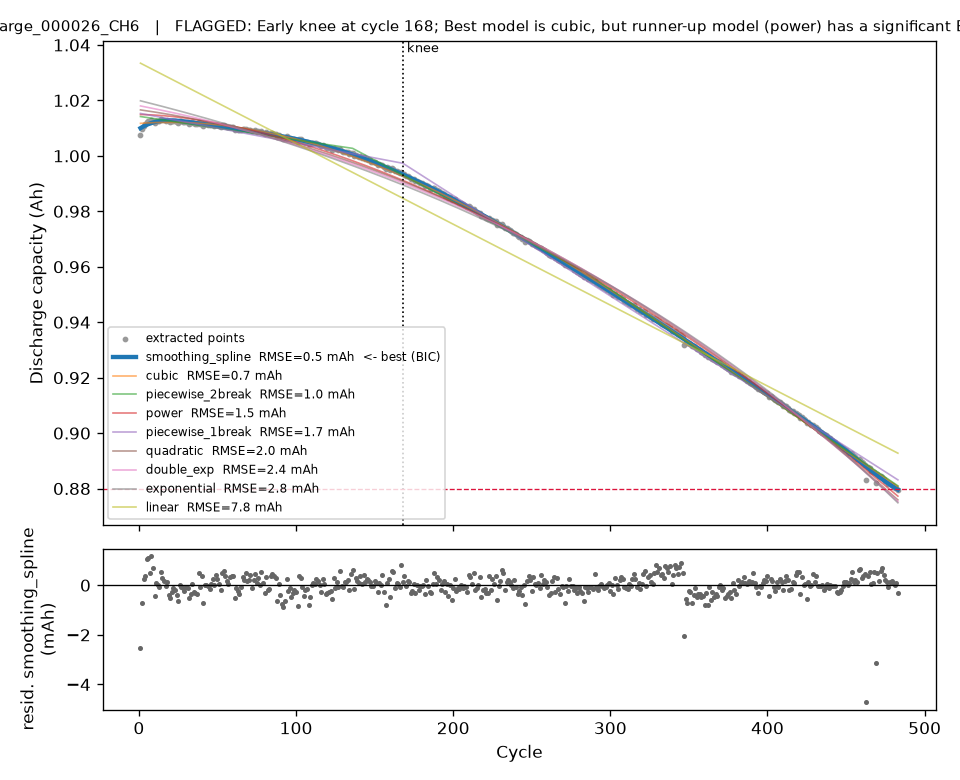


FastCharge_000026_CH5  [high]  knee unusually early in life (at 13% of life, z=-23.04); degradation shape differs from the fleet (cubic beats double_exp)


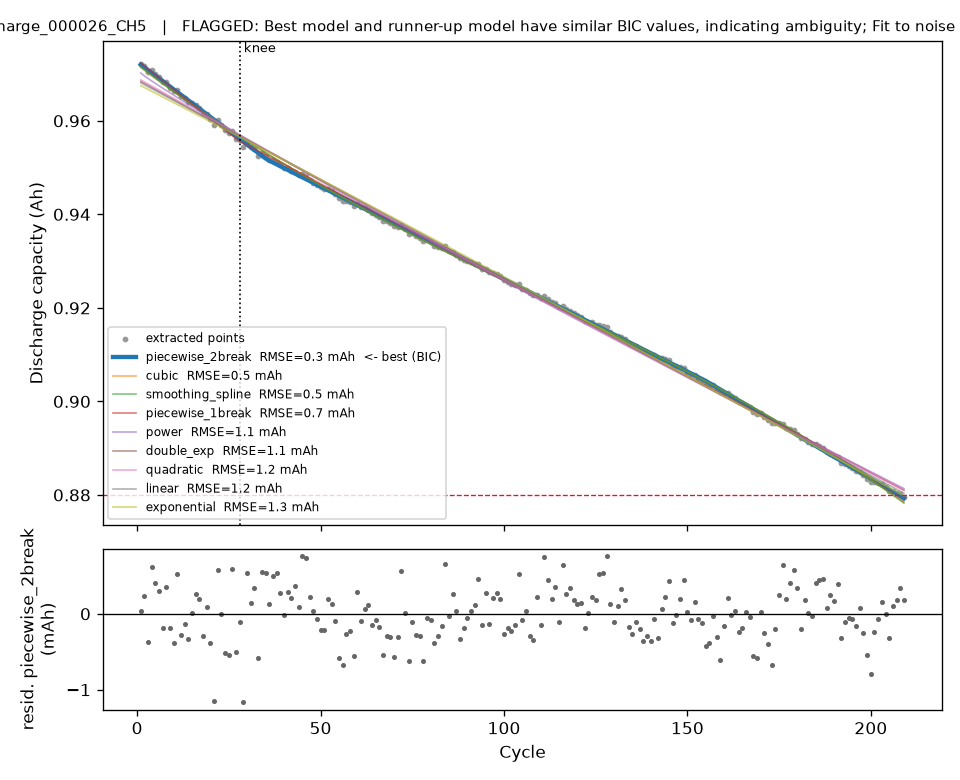


FastCharge_000045_CH1  [high]  knee unusually early in life (at 7% of life, z=-25.38); degradation shape differs from the fleet (piecewise_1break beats double_exp); 67 outlier cycles removed; 6 capacity-recovery jumps


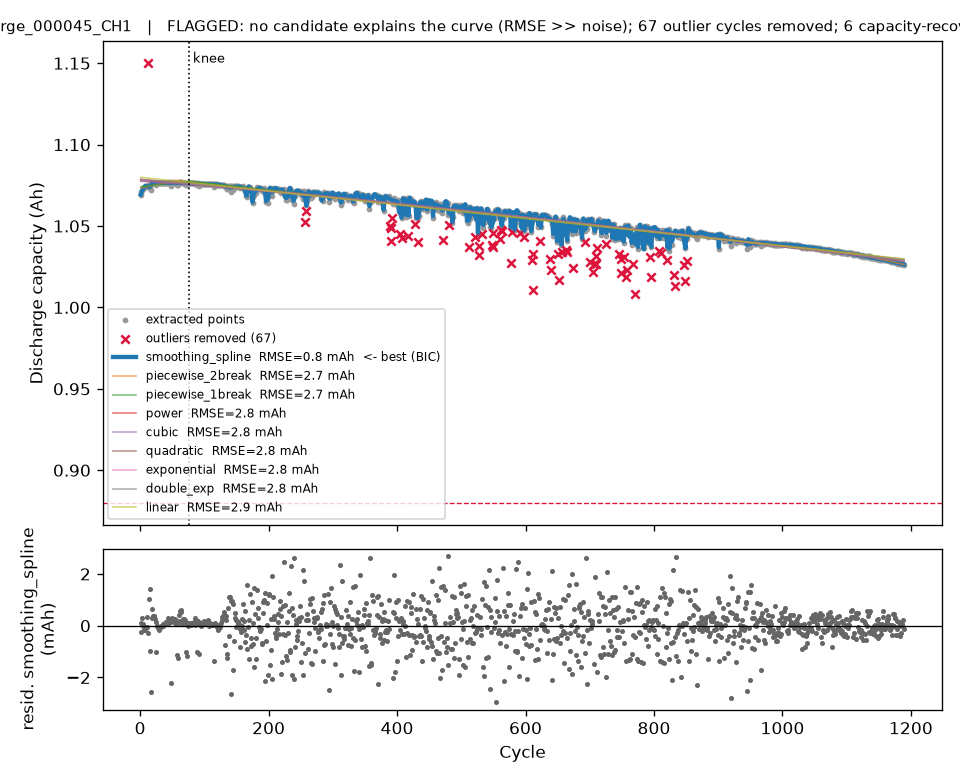


FastCharge_000045_CH2  [high]  knee unusually early in life (at 35% of life, z=-15.48); degradation shape differs from the fleet (cubic beats double_exp)


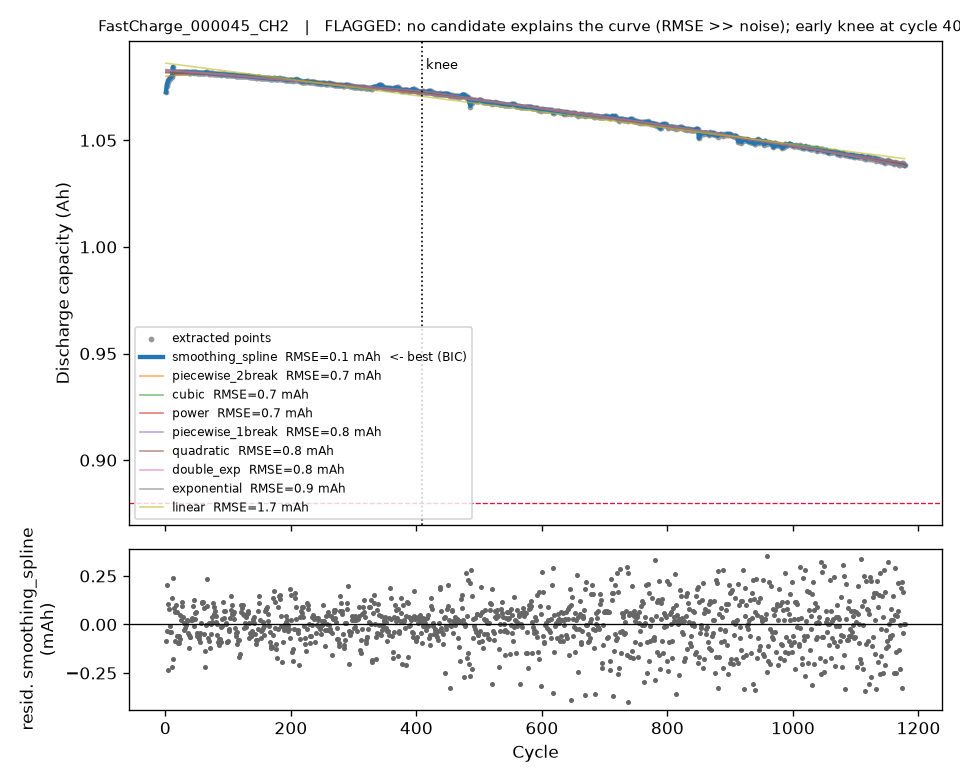


FastCharge_000045_CH3  [high]  knee unusually early in life (at 36% of life, z=-14.95); degradation shape differs from the fleet (power beats double_exp)


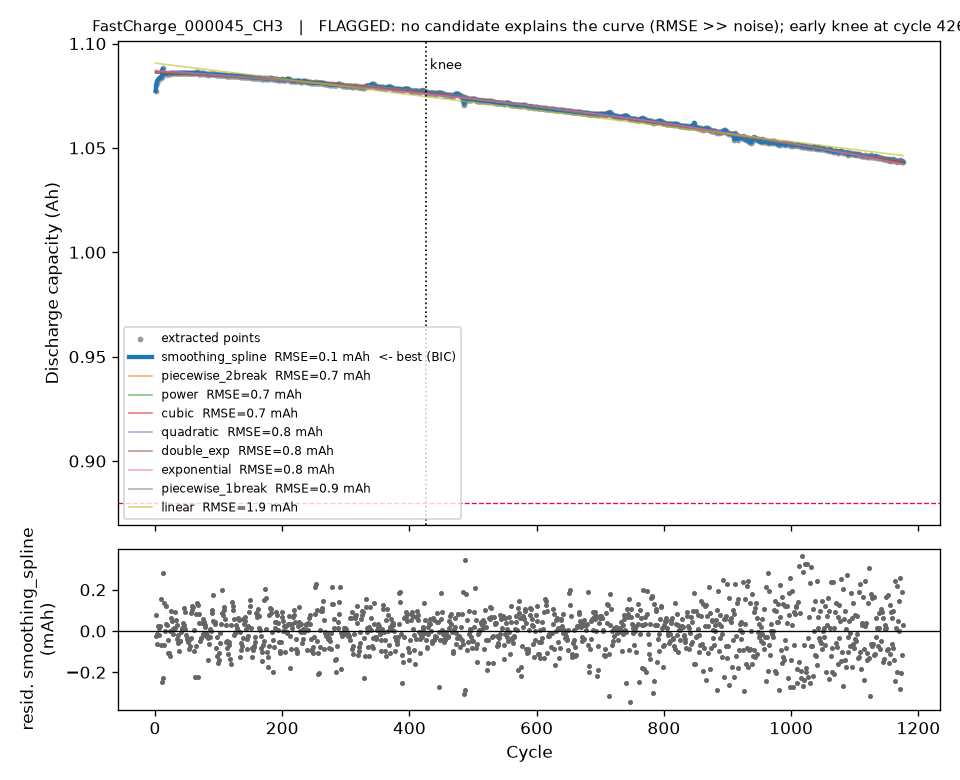


FastCharge_000008_CH47  [high]  knee unusually early in life (at 69% of life, z=-3.3); degradation shape differs from the fleet (cubic beats double_exp)


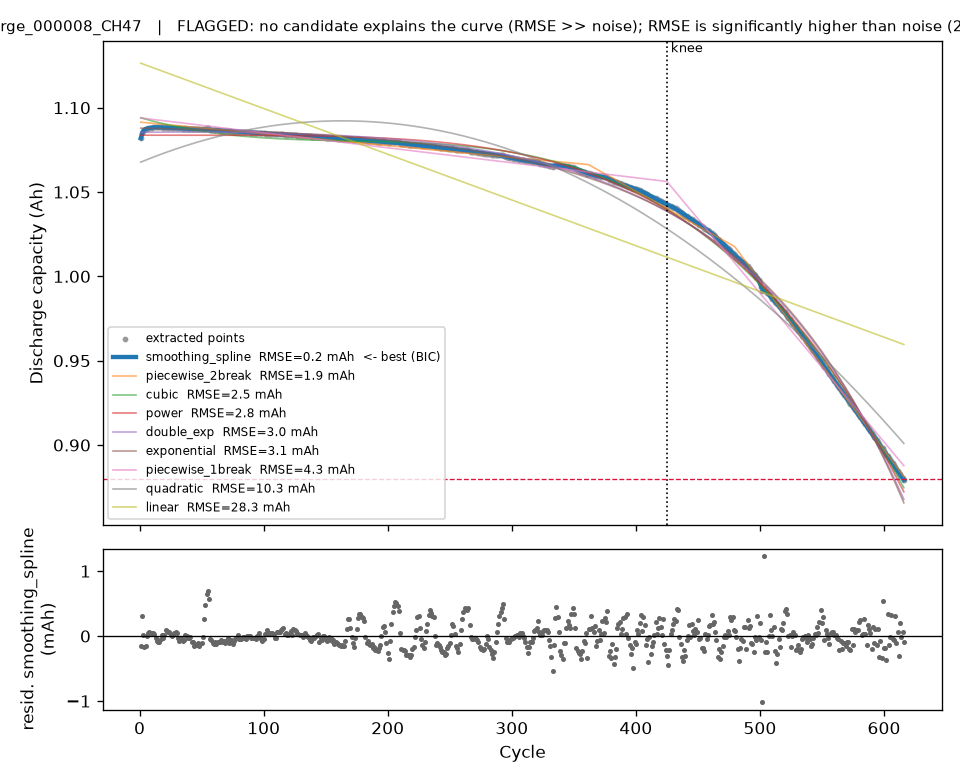


FastCharge_000041_CH10  [high]  knee unusually early in life (at 63% of life, z=-5.5); degradation shape differs from the fleet (cubic beats double_exp)


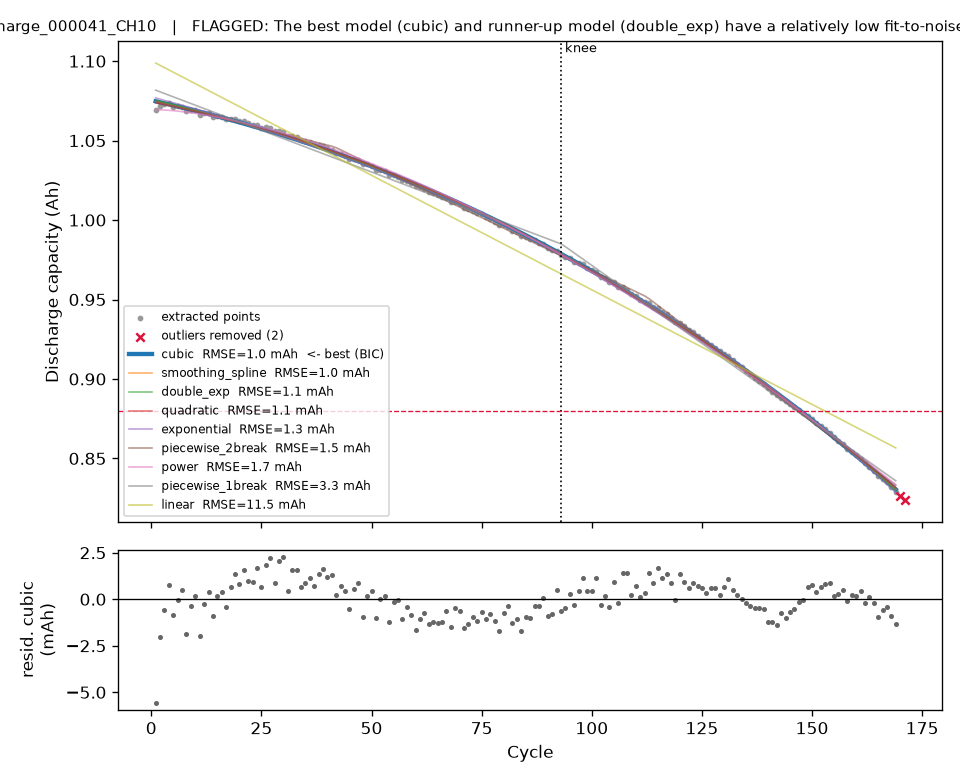


FastCharge_000068_CH38  [high]  degradation shape differs from the fleet (power beats double_exp); 3 outlier cycles removed


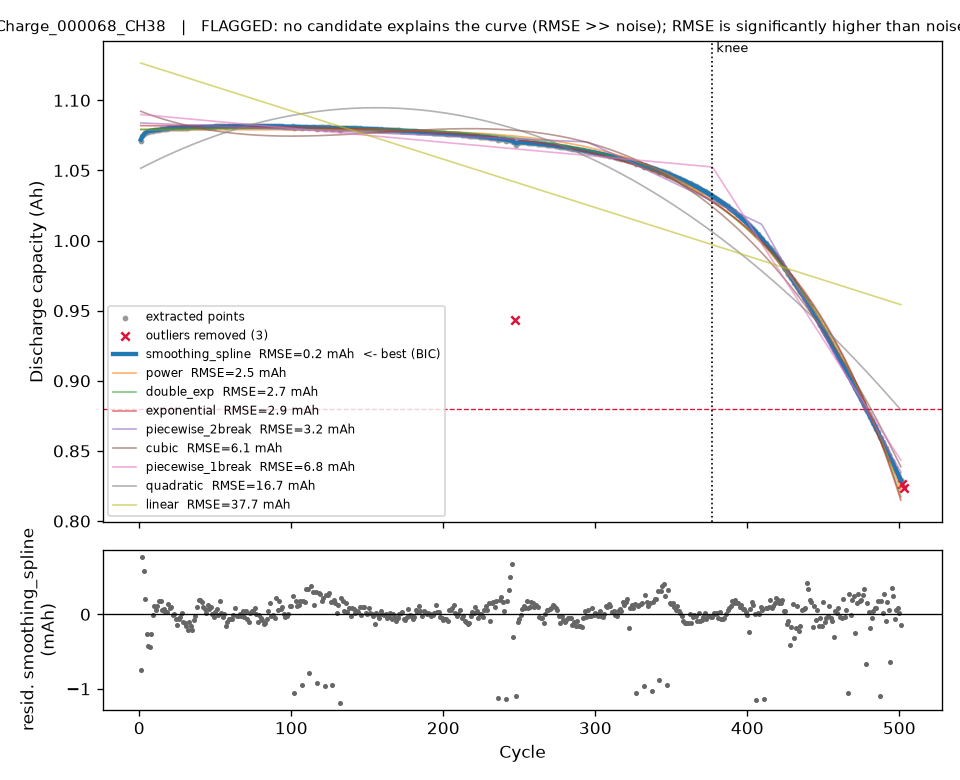


FastCharge_000003_CH40  [high]  exponential and double_exp statistically tied (dBIC=0.3); degradation shape differs from the fleet (exponential beats double_exp)


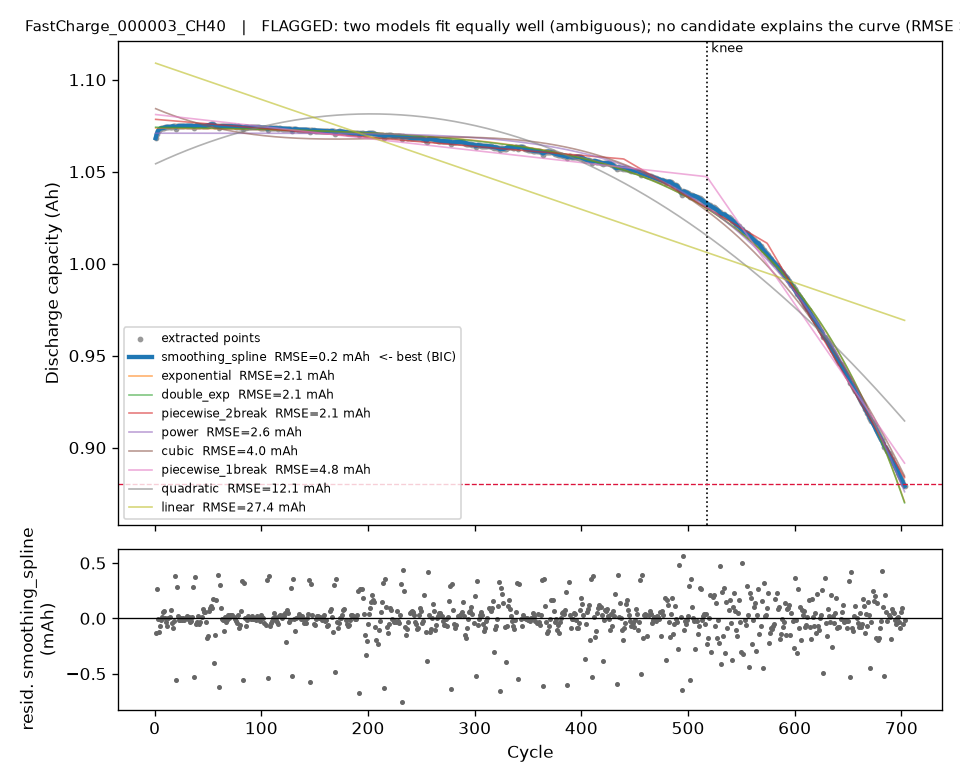


FastCharge_000062_CH47  [high]  degradation shape differs from the fleet (exponential beats double_exp); 4 outlier cycles removed


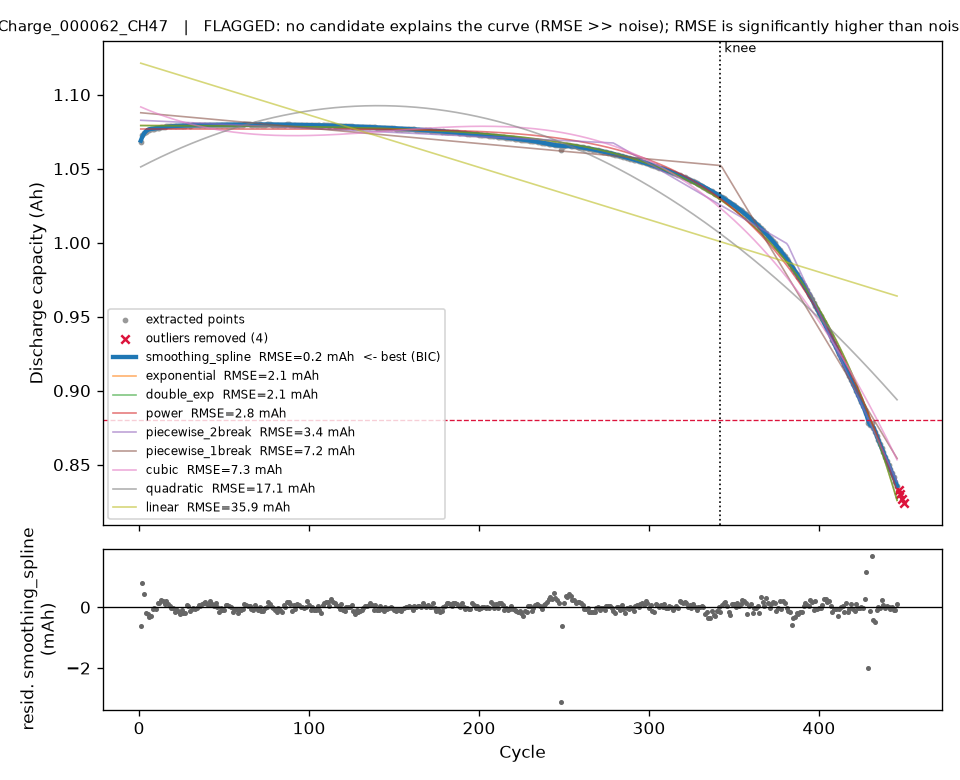

In [12]:
# Plots for the high-priority part of the fleet-relative shortlist
from IPython.display import Image, display
for _, r in wf[wf["priority"] == "high"].iterrows():
    print(f"\n{r.cell_id}  [{r.priority}]  " + "; ".join(r.reasons))
    display(Image(os.path.join(PLOT_DIR, f"{r.cell_id}.png")))